<a href="https://colab.research.google.com/github/vinod-4444/Aerofit-Descriptive-Stats-and-Probability/blob/main/capstone(EHR_DATA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
admission_df=pd.read_csv("ADMISSIONS.csv")
cpt_df=pd.read_csv("CPTEVENTS.csv")
icustay_df=pd.read_csv("ICUSTAYS.csv")
patients_df=pd.read_csv("PATIENTS.csv")

In [ ]:
admission_df.sample(10)

,row_id,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag
57,39821,40124,126179,2130-02-04 2:26:00,2130-02-10 17:39:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,CATHOLIC,SINGLE,WHITE,2130-02-04 0:20:00,2130-02-04 4:09:00,SHORTNESS OF BREATH,0
72,39980,40687,129273,2155-03-08 2:35:00,2155-03-11 15:00:00,2155-03-12 15:00:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,NOT SPECIFIED,WIDOWED,WHITE,2155-03-07 18:24:00,2155-03-08 3:45:00,ABDOMINAL PAIN,1
97,40488,42199,178513,2117-03-21 12:55:00,2117-03-31 12:10:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,PROTESTANT QUAKER,MARRIED,WHITE,2117-03-21 6:05:00,2117-03-21 15:03:00,CHEST PAIN,0
52,12378,10124,170883,2192-04-16 20:57:00,2192-05-15 19:28:00,2192-05-15 19:28:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,RUSS,JEWISH,WIDOWED,WHITE,2192-04-16 11:51:00,2192-04-16 21:38:00,CONGESTIVE HEART FAILURE,1
46,12368,10117,187023,2138-06-05 17:23:00,2138-06-11 10:16:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Private,NaN,CATHOLIC,SINGLE,UNKNOWN/NOT SPECIFIED,2138-06-05 11:42:00,2138-06-05 21:20:00,FEVER,0
74,40350,41795,118192,2145-09-06 8:52:00,2145-09-09 16:25:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,NOT SPECIFIED,MARRIED,WHITE,2145-09-05 22:24:00,2145-09-06 10:14:00,ASTHMA;CHRONIC OBST PULM DISEASE,0
81,40401,41976,130681,2200-10-29 20:46:00,2200-11-03 18:45:00,NaN,EMERGENCY,CLINIC REFERRAL/PREMATURE,Medicare,SPAN,CATHOLIC,MARRIED,HISPANIC/LATINO - PUERTO RICAN,2200-10-29 16:44:00,2200-10-29 22:20:00,FEVER,0
47,12369,10117,105150,2138-11-09 18:08:00,2138-11-18 23:13:00,2138-11-18 23:13:00,EMERGENCY,EMERGENCY ROOM ADMIT,Private,NaN,CATHOLIC,SINGLE,UNKNOWN/NOT SPECIFIED,2138-11-09 15:42:00,2138-11-09 20:42:00,FEVER,1
3,12269,10017,199207,2149-05-26 17:19:00,2149-06-03 18:42:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,NaN,CATHOLIC,DIVORCED,WHITE,2149-05-26 12:08:00,2149-05-26 19:45:00,HUMERAL FRACTURE,0
51,12377,10124,182664,2192-03-26 15:30:00,2192-04-05 14:21:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,RUSS,JEWISH,WIDOWED,WHITE,2192-03-26 10:58:00,2192-03-26 16:48:00,LEFT HIP FRACTURE,0


In [ ]:
cpt_df.sample(10)

,row_id,subject_id,hadm_id,costcenter,chartdate,cpt_cd,sectionheader,subsectionheader,description
1045,255374,40177,198480,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
1354,488538,10119,157466,Resp,2117-08-07 0:00:00,94003,Medicine,Pulmonary,VENT MGMT;SUBSQ DAYS(INVASIVE)
460,205026,42281,195911,ICU,NaN,99232,Evaluation and management,Hospital inpatient services,NaN
1024,254215,40310,186361,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
1023,254214,40310,186361,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
793,242238,44083,125157,ICU,NaN,15734,Surgery,Integumentary system,NaN
1519,542381,42367,139932,Resp,2147-10-12 0:00:00,94003,Medicine,Pulmonary,VENT MGMT;SUBSQ DAYS(INVASIVE)
1262,448656,41976,145024,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
810,247469,42135,102203,ICU,NaN,99232,Evaluation and management,Hospital inpatient services,NaN
471,205037,42281,195911,ICU,NaN,99291,Evaluation and management,Critical care services,NaN


In [ ]:
icustay_df.sample(10)

,row_id,subject_id,hadm_id,icustay_id,first_careunit,last_careunit,first_wardid,last_wardid,intime,outtime,los
66,41424,40304,174997,261743,MICU,MICU,50,50,2163-11-21 18:34:25,2163-11-22 22:06:43,1.1474
5,12762,10026,103770,277021,SICU,SICU,33,33,2195-05-17 7:40:18,2195-05-19 17:24:25,2.4056
127,42615,43909,167612,297782,MICU,MICU,52,52,2152-10-09 19:05:36,2152-10-09 23:39:43,0.1904
58,12875,10132,197611,292910,MICU,MICU,52,52,2123-08-23 20:03:32,2123-08-24 15:11:37,0.7973
116,42565,43735,112662,283181,CCU,CCU,7,7,2128-11-08 13:03:05,2128-11-10 1:00:14,1.4980
17,12780,10045,126949,203766,MICU,SICU,50,57,2129-11-24 22:46:57,2129-12-01 6:03:55,6.3034
64,41415,40277,127703,219013,MICU,MICU,50,50,2151-08-13 12:22:00,2151-08-14 18:39:18,1.2620
76,41546,40687,129273,279183,MICU,MICU,52,52,2155-03-10 1:54:58,2155-03-11 17:58:58,1.6694
75,41540,40655,126002,220016,MICU,MICU,50,50,2144-07-18 22:35:33,2144-07-19 15:44:34,0.7146
119,42575,43748,121860,239935,MICU,CCU,50,7,2179-04-17 13:13:40,2179-04-21 19:08:55,4.2467


In [ ]:
patients_df.sample(10)

,row_id,subject_id,gender,dob
43,9574,10119,M,2036-03-10 0:00:00
62,30962,40655,F,1844-07-18 0:00:00
49,9587,10132,F,2058-04-23 0:00:00
28,9539,10083,F,2110-03-25 0:00:00
84,31752,43735,M,2046-07-05 0:00:00
64,31277,41795,M,2096-07-25 0:00:00
12,9497,10038,F,2056-01-27 0:00:00
30,9545,10089,M,2046-04-18 0:00:00
26,9531,10074,M,2081-12-26 0:00:00
2,9474,10013,F,2038-09-03 0:00:00


In [ ]:
admission_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   row_id                129 non-null    int64 
 1   subject_id            129 non-null    int64 
 2   hadm_id               129 non-null    int64 
 3   admittime             129 non-null    object
 4   dischtime             129 non-null    object
 5   deathtime             40 non-null     object
 6   admission_type        129 non-null    object
 7   admission_location    129 non-null    object
 8   insurance             129 non-null    object
 9   language              81 non-null     object
 10  religion              128 non-null    object
 11  marital_status        113 non-null    object
 12  ethnicity             129 non-null    object
 13  edregtime             92 non-null     object
 14  edouttime             92 non-null     object
 15  diagnosis             129 non-null    ob

In [ ]:
 # making correct date time
admission_df["admittime"]=pd.to_datetime(admission_df["admittime"])
admission_df["dischtime"]=pd.to_datetime(admission_df["dischtime"])
admission_df["deathtime"]=pd.to_datetime(admission_df["deathtime"])
admission_df["edregtime"]=pd.to_datetime(admission_df["edregtime"])
admission_df["edouttime"]=pd.to_datetime(admission_df["edouttime"])

In [ ]:
admission_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   row_id                129 non-null    int64         
 1   subject_id            129 non-null    int64         
 2   hadm_id               129 non-null    int64         
 3   admittime             129 non-null    datetime64[ns]
 4   dischtime             129 non-null    datetime64[ns]
 5   deathtime             40 non-null     datetime64[ns]
 6   admission_type        129 non-null    object        
 7   admission_location    129 non-null    object        
 8   insurance             129 non-null    object        
 9   language              81 non-null     object        
 10  religion              128 non-null    object        
 11  marital_status        113 non-null    object        
 12  ethnicity             129 non-null    object        
 13  edregtime           

In [ ]:
# Filtering to only categorical columns
categorical_columns = admission_df.select_dtypes(include=['object', 'category']).columns

# Using describe() on only these categorical columns
categorical_description = admission_df[categorical_columns].describe()
categorical_description


,admission_type,admission_location,insurance,language,religion,marital_status,ethnicity,diagnosis
count,129,129,129,81,128,113,129,129
unique,3,5,4,5,10,6,9,95
top,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,CATHOLIC,MARRIED,WHITE,SEPSIS
freq,119,81,98,58,59,60,86,10


In [ ]:
# how many percentage of data is missing in each column
missing_value = pd.DataFrame({
'Missing Value': admission_df.isnull().sum(),
'Percentage': (admission_df.isnull().sum() / len(admission_df))*100})
missing_value.sort_values(by='Percentage', ascending=False)


,Missing Value,Percentage
deathtime,89,68.992248
language,48,37.209302
edouttime,37,28.682171
edregtime,37,28.682171
marital_status,16,12.403101
religion,1,0.775194
row_id,0,0.000000
diagnosis,0,0.000000
ethnicity,0,0.000000
insurance,0,0.000000


In [ ]:
from sklearn.impute import SimpleImputer
# set of columns
num_missing = ['language', 'marital_status', 'religion']
# imputing with most frequent values
mode_imputer = SimpleImputer(strategy="most_frequent")
for col in num_missing:
  admission_df[col] = pd.DataFrame(mode_imputer.fit_transform(pd.DataFrame(admission_df[col])))


In [ ]:
# how many percentage of data is missing in each column
missing_value = pd.DataFrame({
'Missing Value': admission_df.isnull().sum(),
'Percentage': (admission_df.isnull().sum() / len(admission_df))*100})
missing_value.sort_values(by='Percentage', ascending=False)

,Missing Value,Percentage
deathtime,89,68.992248
edouttime,37,28.682171
edregtime,37,28.682171
row_id,0,0.000000
language,0,0.000000
diagnosis,0,0.000000
ethnicity,0,0.000000
marital_status,0,0.000000
religion,0,0.000000
insurance,0,0.000000


In [ ]:
patients_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   row_id      100 non-null    int64 
 1   subject_id  100 non-null    int64 
 2   gender      100 non-null    object
 3   dob         100 non-null    object
dtypes: int64(2), object(2)
memory usage: 3.2+ KB


In [ ]:
patients_df['dob']= pd.to_datetime(patients_df['dob'])


In [ ]:
patients_df.sample(10)

,row_id,subject_id,gender,dob
51,30839,40177,M,2082-06-27
48,9585,10130,M,2109-07-08
45,9579,10124,F,2108-12-20
23,9523,10065,F,2111-07-18
10,9494,10035,M,2053-04-13
82,31429,42430,M,2061-12-10
99,31872,44228,F,2112-10-22
6,9487,10027,F,2108-01-15
59,30946,40595,F,2068-03-04
5,9486,10026,F,1895-05-17


In [ ]:
#checking null values
patients_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   row_id      100 non-null    int64         
 1   subject_id  100 non-null    int64         
 2   gender      100 non-null    object        
 3   dob         100 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 3.2+ KB


In [ ]:
icustay_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   row_id          136 non-null    int64  
 1   subject_id      136 non-null    int64  
 2   hadm_id         136 non-null    int64  
 3   icustay_id      136 non-null    int64  
 4   first_careunit  136 non-null    object 
 5   last_careunit   136 non-null    object 
 6   first_wardid    136 non-null    int64  
 7   last_wardid     136 non-null    int64  
 8   intime          136 non-null    object 
 9   outtime         136 non-null    object 
 10  los             136 non-null    float64
dtypes: float64(1), int64(6), object(4)
memory usage: 11.8+ KB


In [ ]:
cpt_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1579 entries, 0 to 1578
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   row_id            1579 non-null   int64 
 1   subject_id        1579 non-null   int64 
 2   hadm_id           1579 non-null   int64 
 3   costcenter        1579 non-null   object
 4   chartdate         291 non-null    object
 5   cpt_cd            1579 non-null   int64 
 6   sectionheader     1579 non-null   object
 7   subsectionheader  1579 non-null   object
 8   description       291 non-null    object
dtypes: int64(4), object(5)
memory usage: 111.1+ KB


In [ ]:
combined_df=pd.merge(patients_df, admission_df, on='subject_id', how="inner")
combined_df.sample(10)



,row_id_x,subject_id,gender,dob,row_id_y,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag
5,9486,10026,F,1895-05-17,12277,103770,2195-05-17 07:39:00,2195-05-24 11:45:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,OTHER,MARRIED,WHITE,2195-05-17 01:49:00,2195-05-17 08:29:00,STROKE/TIA,0
67,30924,40503,F,2097-11-14,39929,168803,2186-07-06 19:59:00,2186-07-07 19:00:00,2186-07-07 19:00:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,ENGL,UNOBTAINABLE,DIVORCED,WHITE,NaT,NaT,STEMI;,1
48,9574,10119,M,2036-03-10,12371,157466,2117-08-05 18:27:00,2117-08-19 16:15:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,NOT SPECIFIED,MARRIED,WHITE,2117-08-05 12:10:00,2117-08-05 19:48:00,ACUTE CHOLECYSTITIS,0
55,9585,10130,M,2109-07-08,12385,156668,2161-01-30 16:26:00,2161-02-19 14:05:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Private,ENGL,CATHOLIC,MARRIED,UNKNOWN/NOT SPECIFIED,2161-01-30 10:35:00,2161-01-30 20:25:00,ABSCESS,0
92,31323,42033,F,2045-10-07,40422,154156,2131-07-26 17:13:00,2131-07-28 16:02:00,2131-07-28 16:02:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,ROMANIAN EAST. ORTH,MARRIED,WHITE,2131-07-26 15:01:00,2131-07-26 18:24:00,SHORTNESS OF BREATH,1
18,9505,10046,F,2141-03-15,12296,133110,2194-07-26 23:43:00,2194-08-06 15:12:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicaid,ENGL,CATHOLIC,SINGLE,WHITE,2194-07-26 19:40:00,2194-07-27 01:46:00,BRAIN METASTASES,0
27,9531,10074,M,2081-12-26,12324,170119,2167-02-11 22:10:00,2167-02-19 15:30:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,OTHER,MARRIED,WHITE,2167-02-11 19:11:00,2167-02-11 22:52:00,GASTROINTESTINAL BLEED,0
108,31429,42430,M,2061-12-10,40554,100969,2142-11-26 21:20:00,2142-11-30 10:55:00,2142-11-30 10:55:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,CHRISTIAN SCIENTIST,MARRIED,WHITE,2142-11-26 18:08:00,2142-11-26 22:18:00,CEREBROVASCULAR ACCIDENT,1
95,31350,42135,M,2083-09-20,40462,102203,2127-07-23 15:21:00,2127-08-04 16:00:00,NaT,EMERGENCY,CLINIC REFERRAL/PREMATURE,Medicaid,ENGL,MUSLIM,MARRIED,AMERICAN INDIAN/ALASKA NATIVE FEDERALLY RECOGN...,NaT,NaT,FAILURE TO THRIVE,0
40,9557,10102,M,2035-04-13,12353,164869,2105-05-29 18:18:00,2105-06-11 02:20:00,2105-06-11 02:20:00,EMERGENCY,CLINIC REFERRAL/PREMATURE,Medicare,ENGL,CATHOLIC,MARRIED,WHITE,NaT,NaT,CHRONIC MYELOGENOUS LEUKEMIA;TRANSFUSION REACTION,1


In [ ]:
merged_df=pd.merge(combined_df, cpt_df, on=['subject_id','hadm_id'],how="inner")
merged_df.sample(10)


,row_id_x,subject_id,gender,dob,row_id_y,hadm_id,admittime,dischtime,deathtime,admission_type,...,edouttime,diagnosis,hospital_expire_flag,row_id,costcenter,chartdate,cpt_cd,sectionheader,subsectionheader,description
195,9519,10061,F,2031-05-19,12311,145203,2107-01-16 11:33:00,2107-02-10 11:30:00,NaT,EMERGENCY,...,NaT,CHEST PAIN/ CATH,0,488285,Resp,2107-01-25 0:00:00,94003,Medicine,Pulmonary,VENT MGMT;SUBSQ DAYS(INVASIVE)
272,9544,10088,M,2029-07-09,12338,168233,2107-01-29 04:00:00,2107-02-10 12:00:00,NaT,EMERGENCY,...,2107-01-29 05:46:00,CONGESTIVE HEART FAILURE,0,59505,ICU,NaN,99291,Evaluation and management,Critical care services,NaN
577,9587,10132,F,2058-04-23,12387,197611,2123-08-23 20:00:00,2123-09-17 14:00:00,NaT,EMERGENCY,...,2123-08-23 20:50:00,NON SMALL CELL CANCER;HYPOXIA,0,36362,ICU,NaN,99254,Evaluation and management,Consultations,NaN
1156,31350,42135,M,2083-09-20,40462,102203,2127-07-23 15:21:00,2127-08-04 16:00:00,NaT,EMERGENCY,...,NaT,FAILURE TO THRIVE,0,247470,ICU,NaN,99232,Evaluation and management,Hospital inpatient services,NaN
147,9517,10059,M,2081-01-03,12309,122098,2150-08-22 17:33:00,2150-08-29 18:20:00,2150-08-29 18:20:00,EMERGENCY,...,2150-08-22 18:00:00,LOWER GI BLEED,1,107981,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
1488,31867,44212,F,2078-06-16,41087,163189,2123-11-24 14:14:00,2123-12-30 14:31:00,NaT,EMERGENCY,...,NaT,ACUTE RESPIRATORY DISTRESS SYNDROME;ACUTE RENA...,0,227873,ICU,NaN,90945,Medicine,Dialysis,NaN
802,30876,40310,M,2103-12-05,39869,186361,2144-07-11 15:02:00,2144-11-12 14:40:00,NaT,EMERGENCY,...,NaT,FACIAL NUMBNESS,0,254193,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN
1378,31429,42430,M,2061-12-10,40554,100969,2142-11-26 21:20:00,2142-11-30 10:55:00,2142-11-30 10:55:00,EMERGENCY,...,2142-11-26 22:18:00,CEREBROVASCULAR ACCIDENT,1,277611,ICU,NaN,99291,Evaluation and management,Critical care services,NaN
1129,31337,42075,M,2086-02-04,40448,151323,2166-02-12 17:57:00,2166-02-26 00:00:00,2166-02-26 00:00:00,EMERGENCY,...,NaT,INFERIOR MYOCARDIAL INFARCTION\CATH,1,223413,ICU,NaN,99291,Evaluation and management,Critical care services,NaN
438,9579,10124,F,2108-12-20,12378,170883,2192-04-16 20:57:00,2192-05-15 19:28:00,2192-05-15 19:28:00,EMERGENCY,...,2192-04-16 21:38:00,CONGESTIVE HEART FAILURE,1,136184,ICU,NaN,99233,Evaluation and management,Hospital inpatient services,NaN


In [ ]:
merged_df.drop(['row_id_x','row_id_y','row_id'], axis=1, inplace=True)
merged_df.sample(5)


,subject_id,gender,dob,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,...,edregtime,edouttime,diagnosis,hospital_expire_flag,costcenter,chartdate,cpt_cd,sectionheader,subsectionheader,description
907,40687,F,2073-06-05,129273,2155-03-08 02:35:00,2155-03-11 15:00:00,2155-03-12 15:00:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,...,2155-03-07 18:24:00,2155-03-08 03:45:00,ABDOMINAL PAIN,1,ICU,NaN,99291,Evaluation and management,Critical care services,NaN
76,10038,F,2056-01-27,111115,2144-02-09 17:53:00,2144-02-21 13:30:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,...,2144-02-09 13:35:00,2144-02-09 20:12:00,FAILURE TO THRIVE,0,ICU,NaN,99232,Evaluation and management,Hospital inpatient services,NaN
773,40310,M,2103-12-05,186361,2144-07-11 15:02:00,2144-11-12 14:40:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Private,...,NaT,NaT,FACIAL NUMBNESS,0,ICU,NaN,36620,Surgery,Cardiovascular system,NaN
1162,42135,M,2083-09-20,117105,2127-10-06 21:00:00,2127-10-28 12:50:00,2127-10-28 12:50:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicaid,...,2127-10-06 19:19:00,2127-10-06 22:26:00,HEPATIC ENCEP,1,ICU,NaN,99291,Evaluation and management,Critical care services,NaN
1554,44212,F,2078-06-16,163189,2123-11-24 14:14:00,2123-12-30 14:31:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,...,NaT,NaT,ACUTE RESPIRATORY DISTRESS SYNDROME;ACUTE RENA...,0,ICU,NaN,99232,Evaluation and management,Hospital inpatient services,NaN


In [ ]:
df=pd.merge(merged_df, icustay_df, on=["subject_id","hadm_id"])
df.sample(10)

,subject_id,gender,dob,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,...,description,row_id,icustay_id,first_careunit,last_careunit,first_wardid,last_wardid,intime,outtime,los
378,10117,F,2072-05-05,105150,2138-11-09 18:08:00,2138-11-18 23:13:00,2138-11-18 23:13:00,EMERGENCY,EMERGENCY ROOM ADMIT,Private,...,NaN,12855,282566,TSICU,MICU,33,12,2138-11-12 3:18:24,2138-11-14 19:29:44,2.6745
821,40310,M,2103-12-05,186361,2144-07-11 15:02:00,2144-11-12 14:40:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Private,...,NaN,41429,210989,CCU,MICU,7,52,2144-07-13 3:56:33,2144-08-01 17:46:11,19.5761
381,10119,M,2036-03-10,157466,2117-08-05 18:27:00,2117-08-19 16:15:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,...,VENT MGMT;SUBSQ DAYS(INVASIVE),12857,247686,SICU,SICU,33,33,2117-08-05 21:05:40,2117-08-13 18:44:34,7.9020
599,10126,F,2127-06-04,160445,2171-07-12 06:02:00,2171-08-16 12:00:00,2171-08-16 12:00:00,EMERGENCY,PHYS REFERRAL/NORMAL DELI,Private,...,NaN,12869,249805,SICU,SICU,57,57,2171-07-12 16:13:00,2171-08-17 1:58:23,35.4065
1022,40456,F,2031-08-12,161765,2118-10-06 16:25:00,2118-10-09 13:30:00,NaT,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,...,NaN,41467,242790,MICU,MICU,50,50,2118-10-06 16:26:04,2118-10-08 16:26:32,2.0003
1723,44212,F,2078-06-16,163189,2123-11-24 14:14:00,2123-12-30 14:31:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,...,NaN,42709,239396,MICU,MICU,50,50,2123-11-24 14:14:29,2123-12-25 17:12:19,31.1235
792,40304,M,2086-12-16,174997,2163-11-21 18:34:00,2163-12-01 11:00:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,...,NaN,41425,234424,MICU,MICU,50,50,2163-11-24 16:52:26,2163-11-25 20:31:19,1.1520
820,40310,M,2103-12-05,186361,2144-07-11 15:02:00,2144-11-12 14:40:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Private,...,NaN,41429,210989,CCU,MICU,7,52,2144-07-13 3:56:33,2144-08-01 17:46:11,19.5761
1031,40595,F,2068-03-04,116518,2144-10-15 10:46:00,2144-10-24 09:00:00,NaT,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,...,NaN,41524,276601,SICU,SICU,57,57,2144-10-15 10:47:21,2144-10-24 9:00:07,8.9255
521,10124,F,2108-12-20,170883,2192-04-16 20:57:00,2192-05-15 19:28:00,2192-05-15 19:28:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,...,NaN,12866,237528,MICU,MICU,23,23,2192-04-30 14:50:44,2192-05-15 23:34:21,15.3636


In [ ]:
df.columns

Index(['subject_id', 'gender', 'dob', 'hadm_id', 'admittime', 'dischtime',
       'deathtime', 'admission_type', 'admission_location', 'insurance',
       'language', 'religion', 'marital_status', 'ethnicity', 'edregtime',
       'edouttime', 'diagnosis', 'hospital_expire_flag', 'costcenter',
       'chartdate', 'cpt_cd', 'sectionheader', 'subsectionheader',
       'description', 'row_id', 'icustay_id', 'first_careunit',
       'last_careunit', 'first_wardid', 'last_wardid', 'intime', 'outtime',
       'los'],
      dtype='object')

In [ ]:
df.shape

(1804, 33)

In [ ]:
# Calculate the number of admissions per patient
df_grouped = admission_df.groupby('subject_id')['hadm_id'].count()
df_grouped_sorted = df_grouped.sort_values(ascending=False)
df_grouped_sorted.head(5)


subject_id
41976    15
10088     3
44083     3
40124     2
41795     2
Name: hadm_id, dtype: int64

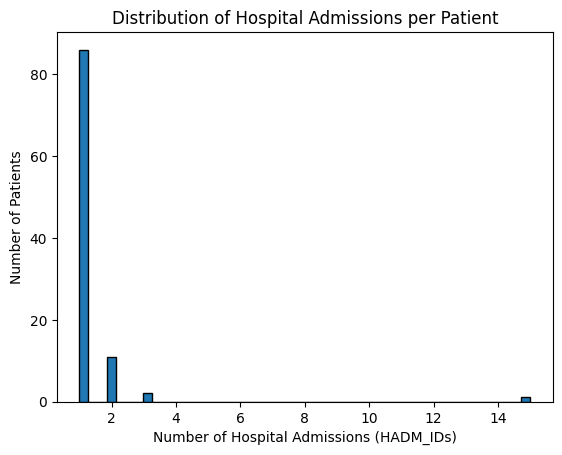

In [ ]:


# Analyze the distribution of admissions
plt.hist(df_grouped, bins=50, edgecolor='black')
plt.xlabel('Number of Hospital Admissions (HADM_IDs)')
plt.ylabel('Number of Patients')
plt.title('Distribution of Hospital Admissions per Patient')

# Save the figure
plt.savefig(r"C:\Users\balav\Documents\capstone\Distribution_of_hospitaladmissions.jpg")

# Display the plot
plt.show()


In [ ]:
# Identify frequent readmissions (modify threshold as needed)
frequent_readmissions = df_grouped[df_grouped >= 3]
# Analyze patients with frequent readmissions (optional)
print("Patients with 3 or more Admissions:")
print(frequent_readmissions.to_string())


Patients with 3 or more Admissions:
subject_id
10088     3
41976    15
44083     3


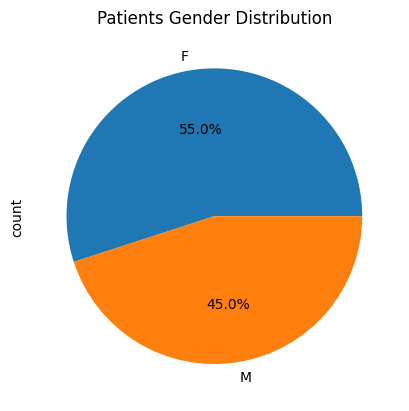

In [ ]:
# Create a value count for the 'Gender' column
gender_counts = patients_df["gender"].value_counts()
# Visualize gender distribution (pie chart or bar chart)
gender_counts.plot(kind='pie', autopct='%1.1f%%') # Pie chart
plt.title('Patients Gender Distribution')
plt.show()




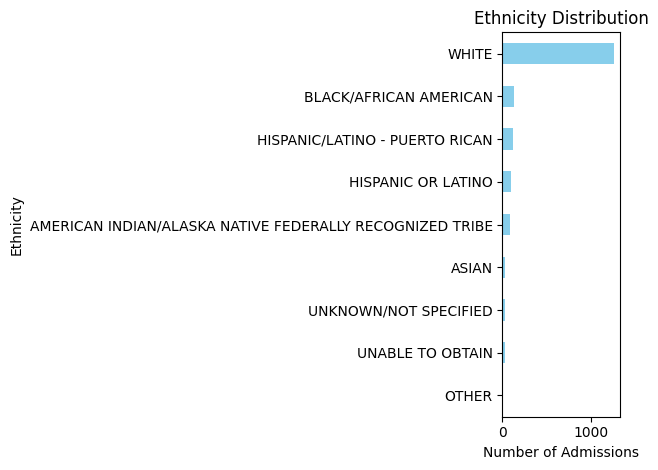

In [ ]:
# Create a value count for the 'Ethnicity' column
ethnicity_counts = df['ethnicity'].value_counts()
# Visualize ethnicity distribution (bar chart)
# Visualize ethnicity distribution (horizontal bar chart)
ethnicity_counts.plot(kind='barh', color='skyblue') # horizontal bar chart␣with color
plt.xlabel('Number of Admissions')
plt.ylabel('Ethnicity')
plt.title('Ethnicity Distribution')
plt.gca().invert_yaxis() # Invert y-axis to display most frequent ethnicity at␣the top
plt.tight_layout() # Adjust layout for better readability
plt.show()


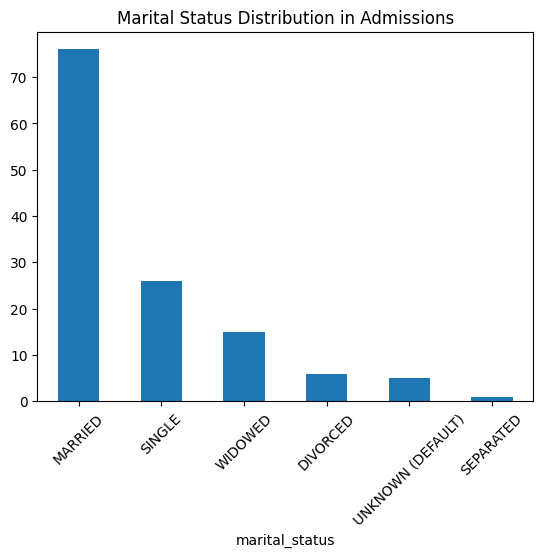

In [ ]:
# Create a value count for the 'Marital Status' column
marital_status_counts = combined_df['marital_status'].value_counts()
# Visualize marital status distribution (bar chart)
marital_status_counts.plot(kind='bar')
plt.title('Marital Status Distribution in Admissions')
plt.xticks(rotation=45) # Rotate x-axis labels for long marital status names
plt.show()


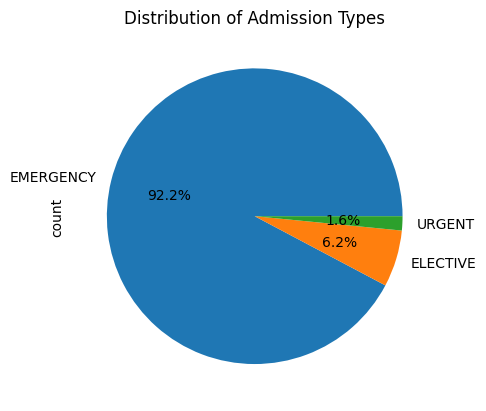

In [ ]:
admission_type_counts=combined_df['admission_type'].value_counts()
admission_type_counts.plot(kind='pie', autopct='%1.1f%%') # Percentages on pie␣slices
plt.title('Distribution of Admission Types')
plt.show()


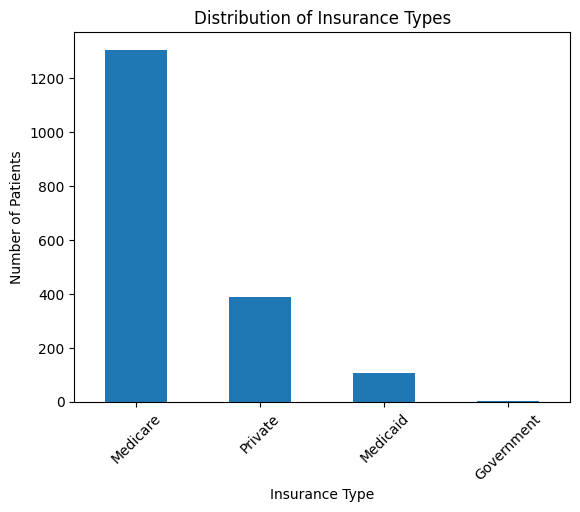

In [ ]:
# Insurance Status
insurance_counts = df['insurance'].value_counts()
insurance_counts.plot(kind='bar')
plt.title('Distribution of Insurance Types')
plt.xlabel('Insurance Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.show()

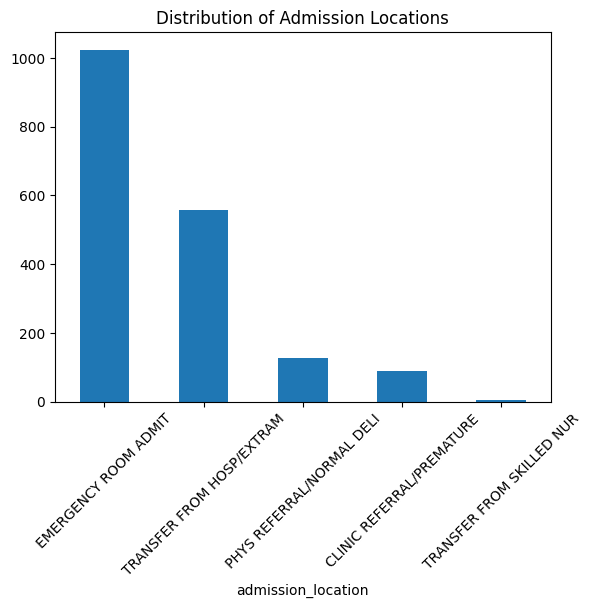

In [ ]:
#admission location and type analysis
admission_location_counts = df['admission_location'].value_counts()
admission_location_counts.plot(kind='bar')
plt.title('Distribution of Admission Locations')
plt.xticks(rotation=45)
plt.show()


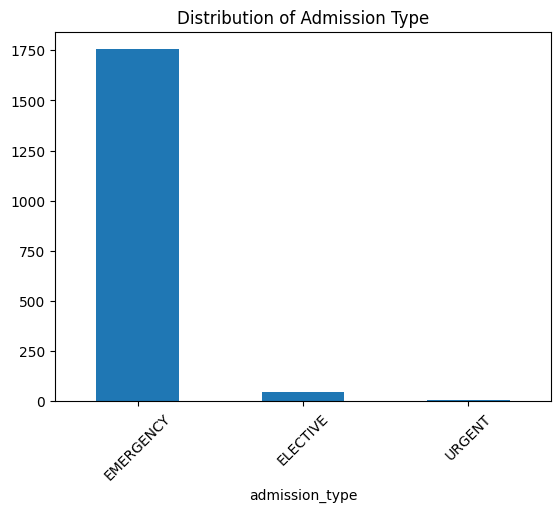

In [ ]:
admission_type_counts = df['admission_type'].value_counts()
admission_type_counts.plot(kind='bar')
plt.title('Distribution of Admission Type')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Filtering to only categorical columns for whole df
categorical_columns_df = df.select_dtypes(include=['object', 'category']).columns

# Using describe() on only these categorical columns
categorical_description_df = df[categorical_columns_df].describe()
categorical_description_df.T


,count,unique,top,freq
gender,1804,2,M,918
admission_type,1804,3,EMERGENCY,1755
admission_location,1804,5,EMERGENCY ROOM ADMIT,1024
insurance,1804,4,Medicare,1306
language,1804,5,ENGL,1414
religion,1804,10,CATHOLIC,747
marital_status,1804,6,MARRIED,768
ethnicity,1804,9,WHITE,1271
diagnosis,1804,86,CONGESTIVE HEART FAILURE,219
costcenter,1804,2,ICU,1472


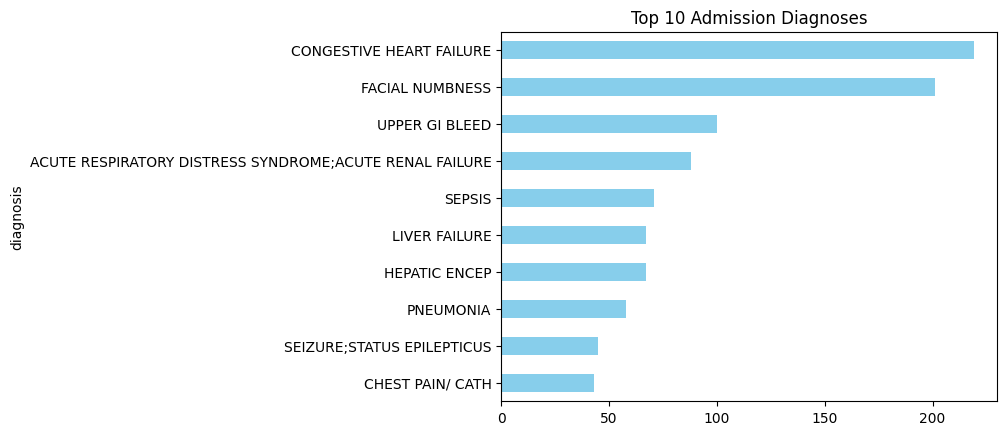

In [ ]:
#analysing diagnosis
diagnosis_counts = df['diagnosis'].value_counts().head(10)
diagnosis_counts.plot(kind='barh', color='skyblue')
plt.title('Top 10 Admission Diagnoses')
plt.gca().invert_yaxis()
plt.show()


In [ ]:
#examining icu admissions and avg length of stay
print("Total ICU Admissions:", df['icustay_id'].nunique())
print("Average Length of ICU Stay:", df['los'].mean())
print("Median Length of ICU Stay:", df['los'].median())
print("Total ICU Admissions with duplicates:", df['icustay_id'].count())


Total ICU Admissions: 125
Average Length of ICU Stay: 10.872162028824832
Median Length of ICU Stay: 5.6857
Total ICU Admissions with duplicates: 1804


In [ ]:
# transfer in icus
icu_transfers = df[df['first_careunit'] != df['last_careunit']]
print("Number of ICU Transfers:", len(icu_transfers))
icu_non_transfers = df[df['first_careunit'] == df['last_careunit']]
print("Number of ICU non Transfers:", len(icu_non_transfers))


Number of ICU Transfers: 277
Number of ICU non Transfers: 1527


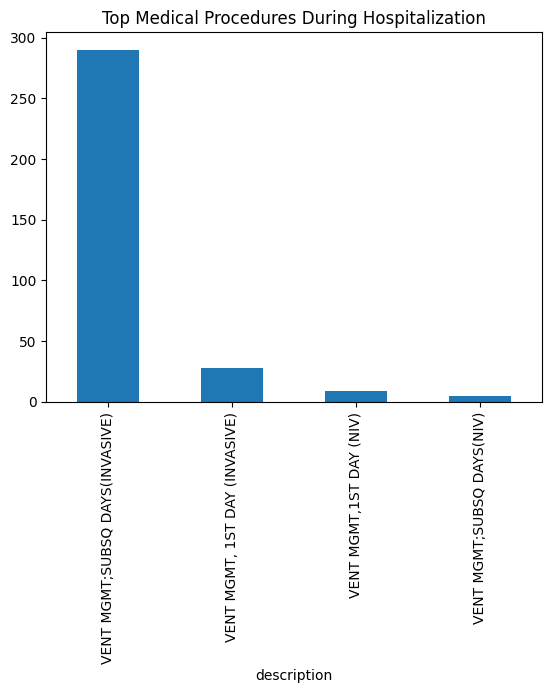

In [ ]:
# frequency of medical procedures
procedure_counts = df['description'].value_counts().head(10)
procedure_counts.plot(kind='bar')
plt.title('Top Medical Procedures During Hospitalization')
plt.xticks(rotation=90)
plt.show()


In [ ]:
# procedure utilisation trends
df['year'] = df['admittime'].dt.year
cpt_trends = df.groupby(['sectionheader', 'year']).size().unstack(fill_value=0)
print(cpt_trends)


year                       2102  2104  2105  2107  2110  2112  2115  2117  \
sectionheader                                                               
Evaluation and management     4    15    17    71    26    20     8    18   
Medicine                      0     0     0    27     0     4     3     7   
Radiology                     0     0     0     0     0     0     0     0   
Surgery                       2     0     0     1     2     5     0     0   

year                       2118  2119  ...  2189  2190  2192  2193  2195  \
sectionheader                          ...                                 
Evaluation and management     3    80  ...     0     1   161     4     6   
Medicine                      1    12  ...     0     2    51     0     0   
Radiology                     0     0  ...     0     0     0     0     0   
Surgery                       0     2  ...     3     0     9     1     0   

year                       2198  2199  2200  2201  2202  
sectionheader         

In [ ]:
# medical procedure relation with hospital mortality
mortality_by_procedure = df.groupby('description')['hospital_expire_flag'].mean()
print(mortality_by_procedure.sort_values(ascending=False).head(10))

description
VENT MGMT,1ST DAY (NIV)           1.000000
VENT MGMT;SUBSQ DAYS(INVASIVE)    0.613793
VENT MGMT;SUBSQ DAYS(NIV)         0.600000
VENT MGMT, 1ST DAY (INVASIVE)     0.571429
Name: hospital_expire_flag, dtype: float64


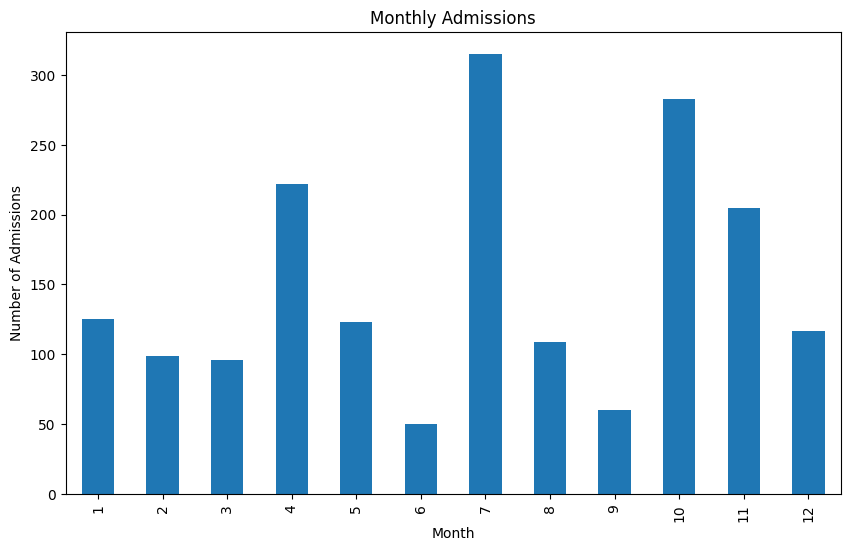

In [ ]:
# Monthly admissions
df['month'] = df['admittime'].dt.month
monthly_admissions = df.groupby('month').size()
plt.figure(figsize=(10, 6))
monthly_admissions.plot(kind='bar')
plt.title('Monthly Admissions')
plt.xlabel('Month')
plt.ylabel('Number of Admissions')
plt.show()

In [ ]:
# Count admissions per patient
readmission_counts = df.groupby('subject_id').size()

# Identifing patients with frequent readmissions (e.g., 3 or more times)
frequent_readmissions = readmission_counts[readmission_counts >= 3]

# Analyzing characteristics of these patients
frequent_readmission_patients = df[df['subject_id'].isin(frequent_readmissions.index)]
print(f"Number of patients with frequent readmissions: {len(frequent_readmission_patients)}")


Number of patients with frequent readmissions: 1784


In [ ]:
# Analyzing mortality rates by diagnosis
mortality_by_diagnosis = df.groupby('diagnosis')['hospital_expire_flag'].mean()
top_mortality_diagnoses = mortality_by_diagnosis.sort_values(ascending=False).head(10)
print("Top 10 Diagnoses by Mortality Rate:\n", top_mortality_diagnoses)

# Analyzing length of stay by admission type
df['LOS'] = (df['dischtime'] - df['admittime']).dt.days
los_by_admission_type = df.groupby('admission_type')['LOS'].mean()
print("Average Length of Stay by Admission Type:\n", los_by_admission_type)


Top 10 Diagnoses by Mortality Rate:
 diagnosis
ABDOMINAL PAIN                                       1.0
CHRONIC MYELOGENOUS LEUKEMIA;TRANSFUSION REACTION    1.0
HEPATIC ENCEP                                        1.0
INFERIOR MYOCARDIAL INFARCTION\CATH                  1.0
ACUTE CHOLANGITIS                                    1.0
LOWER GI BLEED                                       1.0
LUNG CANCER;SHORTNESS OF BREATH                      1.0
METASTIC MELANOMA;ANEMIA                             1.0
PNEUMONIA;TELEMETRY                                  1.0
S/P FALL                                             1.0
Name: hospital_expire_flag, dtype: float64
Average Length of Stay by Admission Type:
 admission_type
ELECTIVE     18.818182
EMERGENCY    28.763533
URGENT        5.000000
Name: LOS, dtype: float64


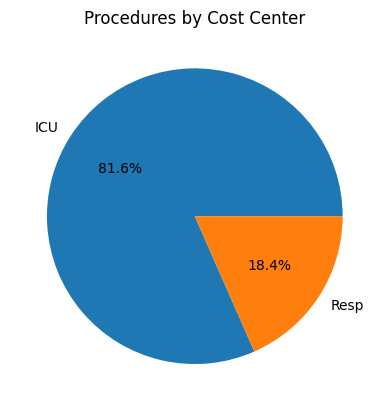

In [ ]:
# Count procedures by costcenter (ICU vs. Non-ICU)
procedure_counts = df.groupby('costcenter').size()
procedure_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Procedures by Cost Center')
plt.show()



Most Common Diagnosis by Ethnicity:
 ethnicity
AMERICAN INDIAN/ALASKA NATIVE FEDERALLY RECOGNIZED TRIBE                                        HEPATIC ENCEP
ASIAN                                                                         LUNG CANCER;SHORTNESS OF BREATH
BLACK/AFRICAN AMERICAN                                      ACUTE RESPIRATORY DISTRESS SYNDROME;ACUTE RENA...
HISPANIC OR LATINO                                                                             UPPER GI BLEED
HISPANIC/LATINO - PUERTO RICAN                                                                         SEPSIS
OTHER                                                                                       FAILURE TO THRIVE
UNABLE TO OBTAIN                                                          INFERIOR MYOCARDIAL INFARCTION\CATH
UNKNOWN/NOT SPECIFIED                                                                           LIVER FAILURE
WHITE                                                                    

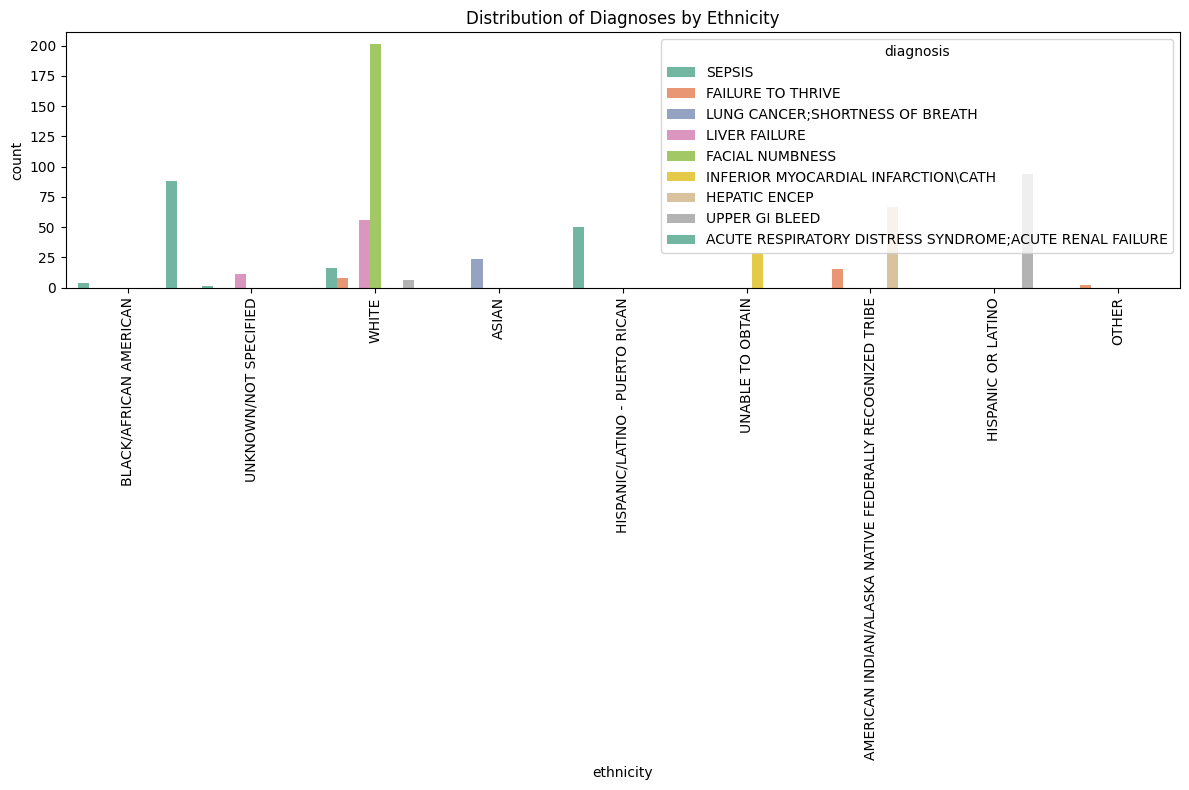

In [ ]:
# Count diagnoses by ethnicity
diagnoses_by_ethnicity = df.groupby('ethnicity')['diagnosis'].value_counts().unstack(fill_value=0)
top_diagnoses_by_ethnicity = diagnoses_by_ethnicity.idxmax(axis=1)
print("Most Common Diagnosis by Ethnicity:\n", top_diagnoses_by_ethnicity)

# Visualising the distribution of diagnoses in different ethnic groups
plt.figure(figsize=(12, 8))
sns.countplot(x='ethnicity', hue='diagnosis', data=df[df['diagnosis'].isin(top_diagnoses_by_ethnicity.values)], palette='Set2')
plt.title('Distribution of Diagnoses by Ethnicity')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
 #Count occurrences of each sectionheader and subsectionheader
section_counts = df['sectionheader'].value_counts()
subsection_counts = df['subsectionheader'].value_counts()

# Count occurrences of each subsectionheader within each sectionheader
section_subsection_counts = df.groupby(['sectionheader', 'subsectionheader']).size().unstack(fill_value=0)

#Analyze relationship between sectionheader and length of stay (los)
section_los = df.groupby('sectionheader')['los'].mean()

#Analyze relationship between subsectionheader and length of stay (los)
subsection_los = df.groupby('subsectionheader')['los'].mean()

# Display results
print("Section Header Counts:\n", section_counts)
print("\nSubsection Header Counts:\n", subsection_counts)
print("\nSubsection Header Counts within each Section Header:\n", section_subsection_counts)
print("\nAverage Length of Stay by Section Header:\n", section_los)
print("\nAverage Length of Stay by Subsection Header:\n", subsection_los)

Section Header Counts:
 sectionheader
Evaluation and management    1323
Medicine                      393
Surgery                        85
Radiology                       3
Name: count, dtype: int64

Subsection Header Counts:
 subsectionheader
Hospital inpatient services                                                                                                                                                  841
Critical care services                                                                                                                                                       384
Pulmonary                                                                                                                                                                    332
Consultations                                                                                                                                                                 89
Dialysis                                       

<ipython-input-49-a1e505b0eb43>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=section_counts.index, y=section_counts.values, palette='viridis')


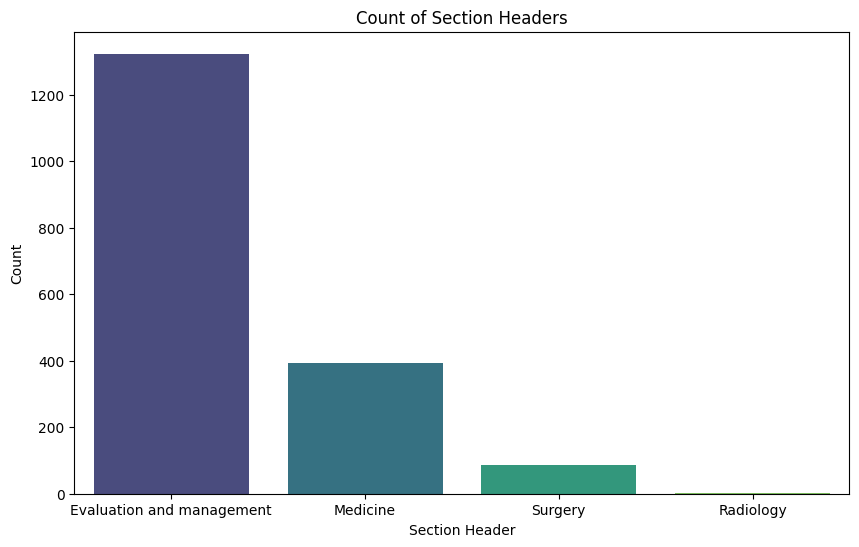

In [ ]:

#Bar chart for sectionheader counts
plt.figure(figsize=(10, 6))
sns.barplot(x=section_counts.index, y=section_counts.values, palette='viridis')
plt.title('Count of Section Headers')
plt.xlabel('Section Header')
plt.ylabel('Count')
plt.show()



<ipython-input-50-ea1bf51ce3ec>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subsection_counts.index, y=subsection_counts.values, palette='viridis')


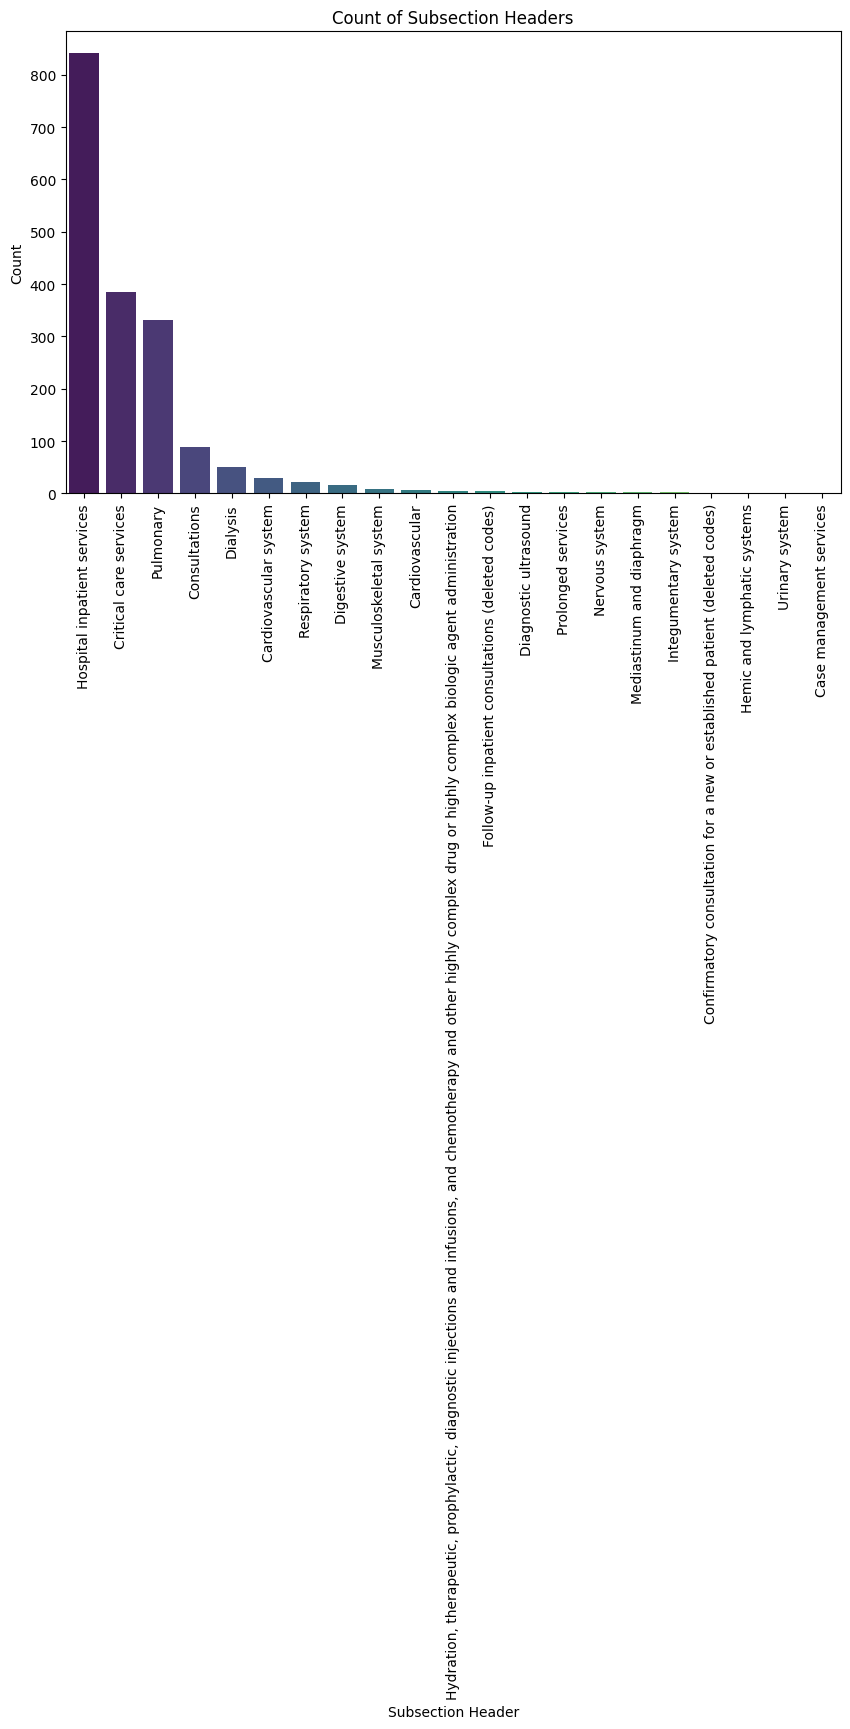

In [ ]:
# Bar chart for subsectionheader counts
plt.figure(figsize=(10, 6))
sns.barplot(x=subsection_counts.index, y=subsection_counts.values, palette='viridis')
plt.title('Count of Subsection Headers')
plt.xlabel('Subsection Header')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()


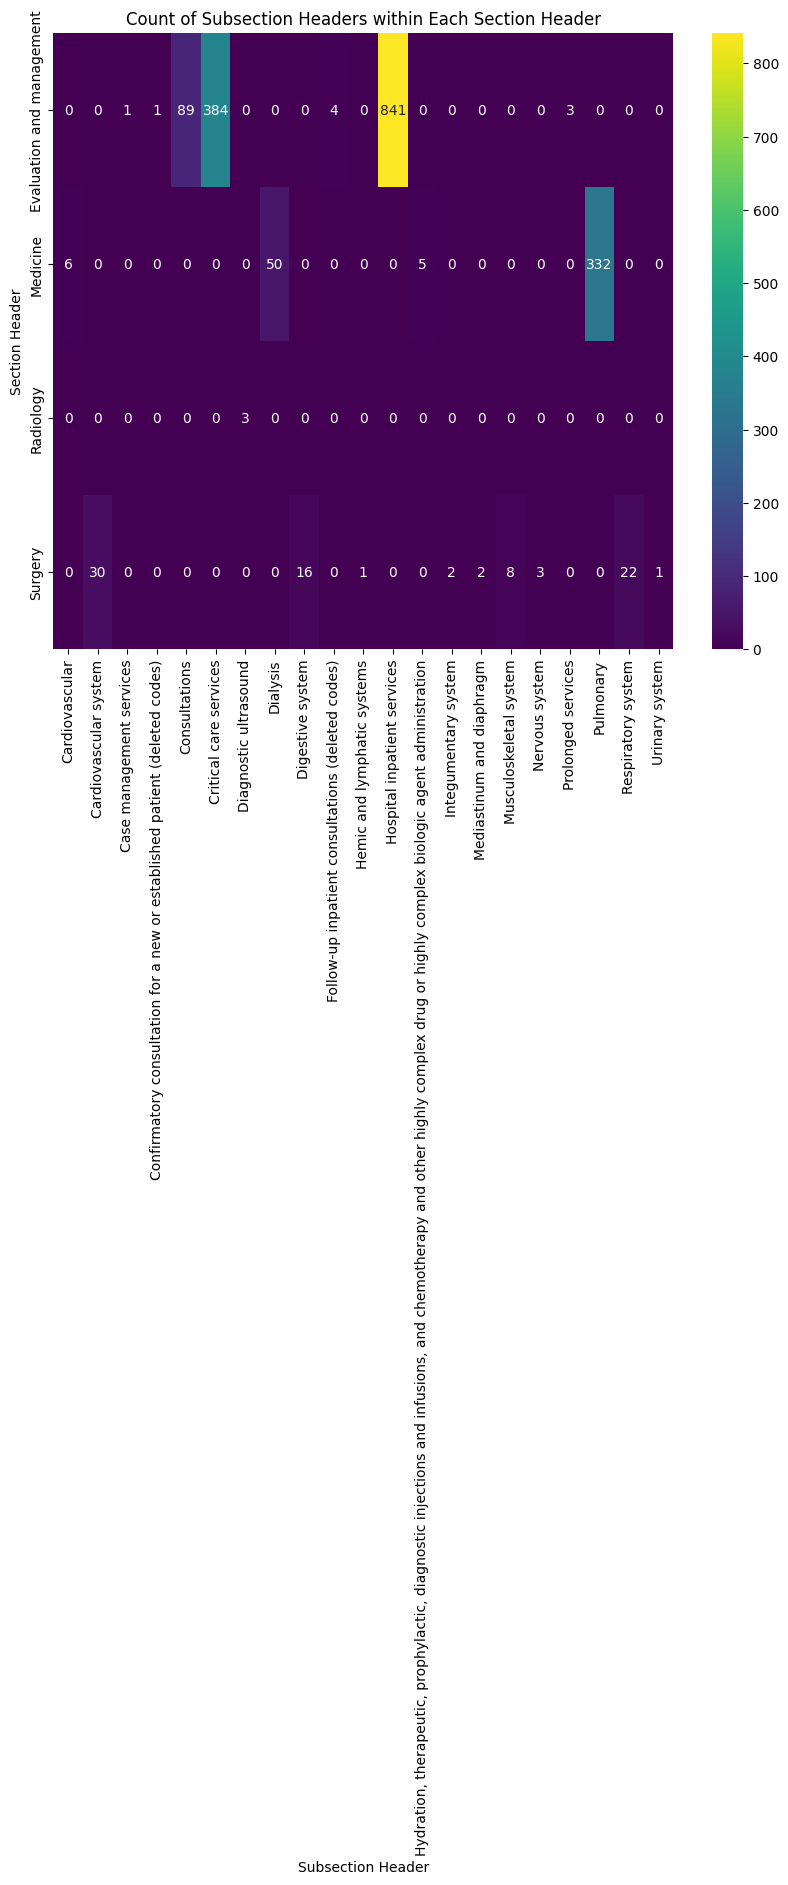

In [ ]:

# Heatmap for subsectionheader counts within each sectionheader
plt.figure(figsize=(10, 8))
sns.heatmap(section_subsection_counts, annot=True, cmap='viridis', fmt='d')
plt.title('Count of Subsection Headers within Each Section Header')
plt.xlabel('Subsection Header')
plt.ylabel('Section Header')
plt.show()


<ipython-input-52-c71ea13e67c8>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=section_los.index, y=section_los.values, palette='viridis')


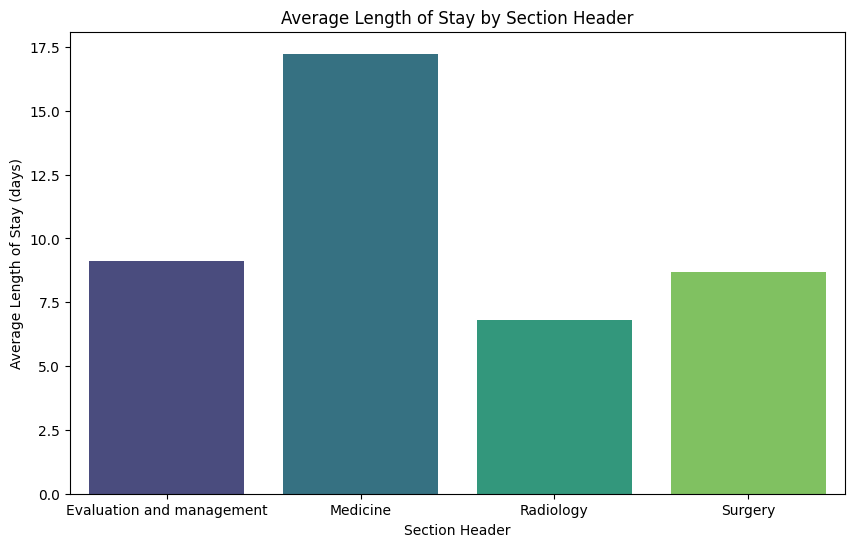

In [ ]:

# Bar chart for average length of stay by sectionheader
plt.figure(figsize=(10, 6))
sns.barplot(x=section_los.index, y=section_los.values, palette='viridis')
plt.title('Average Length of Stay by Section Header')
plt.xlabel('Section Header')
plt.ylabel('Average Length of Stay (days)')
plt.show()


<ipython-input-53-6164a4c4ae74>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subsection_los.index, y=subsection_los.values, palette='viridis')


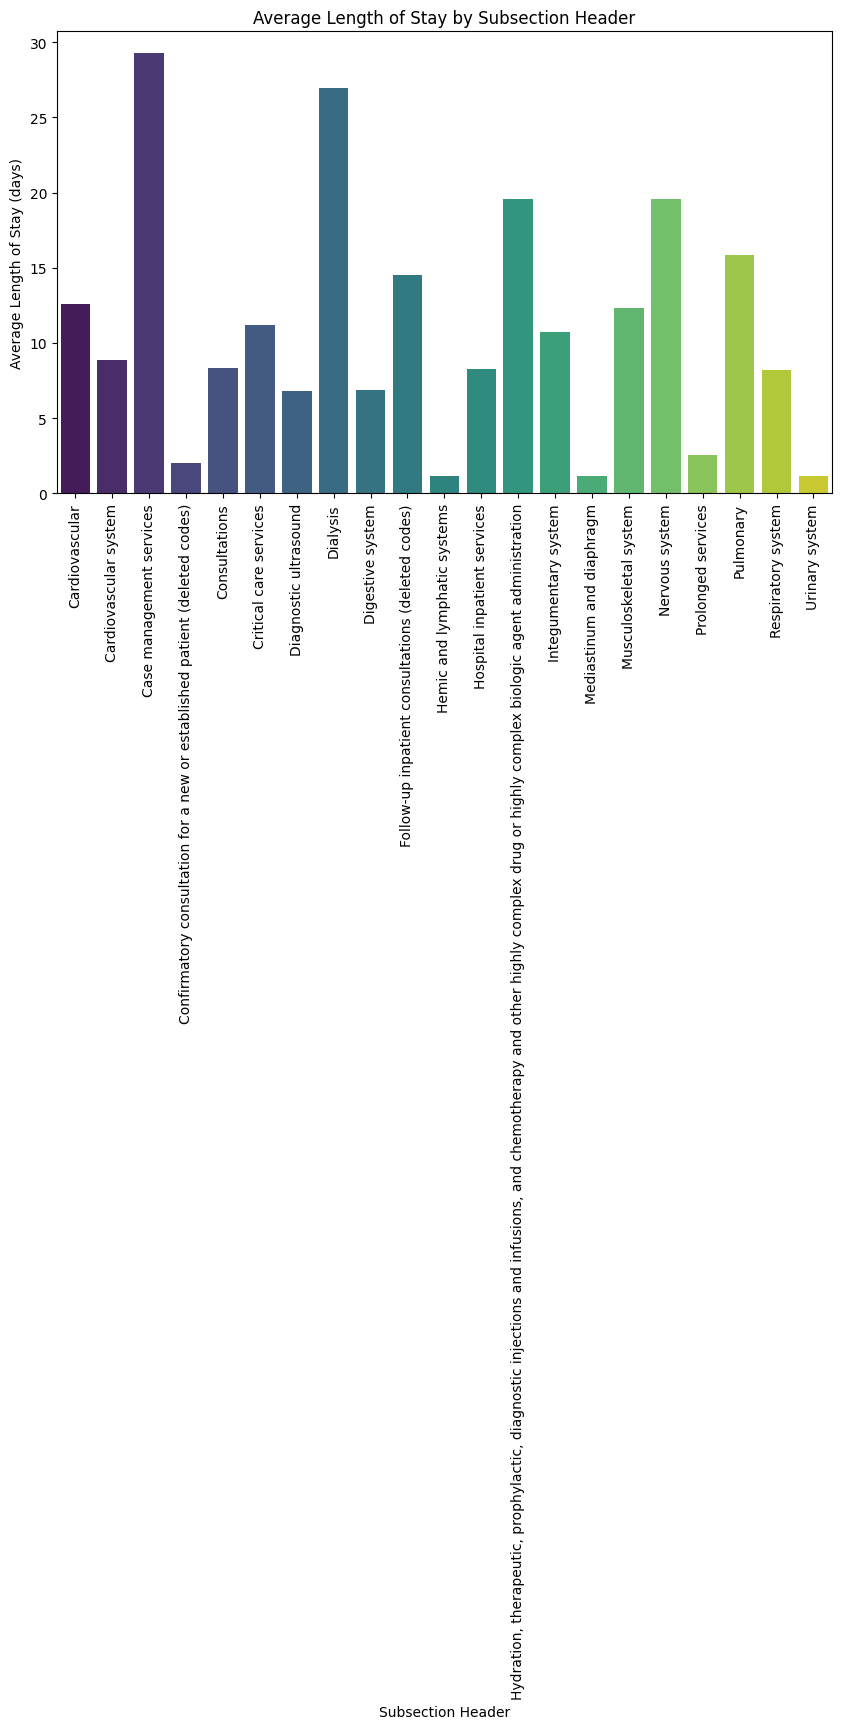

In [ ]:

#Bar chart for average length of stay by subsectionheader
plt.figure(figsize=(10, 6))
sns.barplot(x=subsection_los.index, y=subsection_los.values, palette='viridis')
plt.title('Average Length of Stay by Subsection Header')
plt.xlabel('Subsection Header')
plt.ylabel('Average Length of Stay (days)')
plt.xticks(rotation=90)
plt.show()

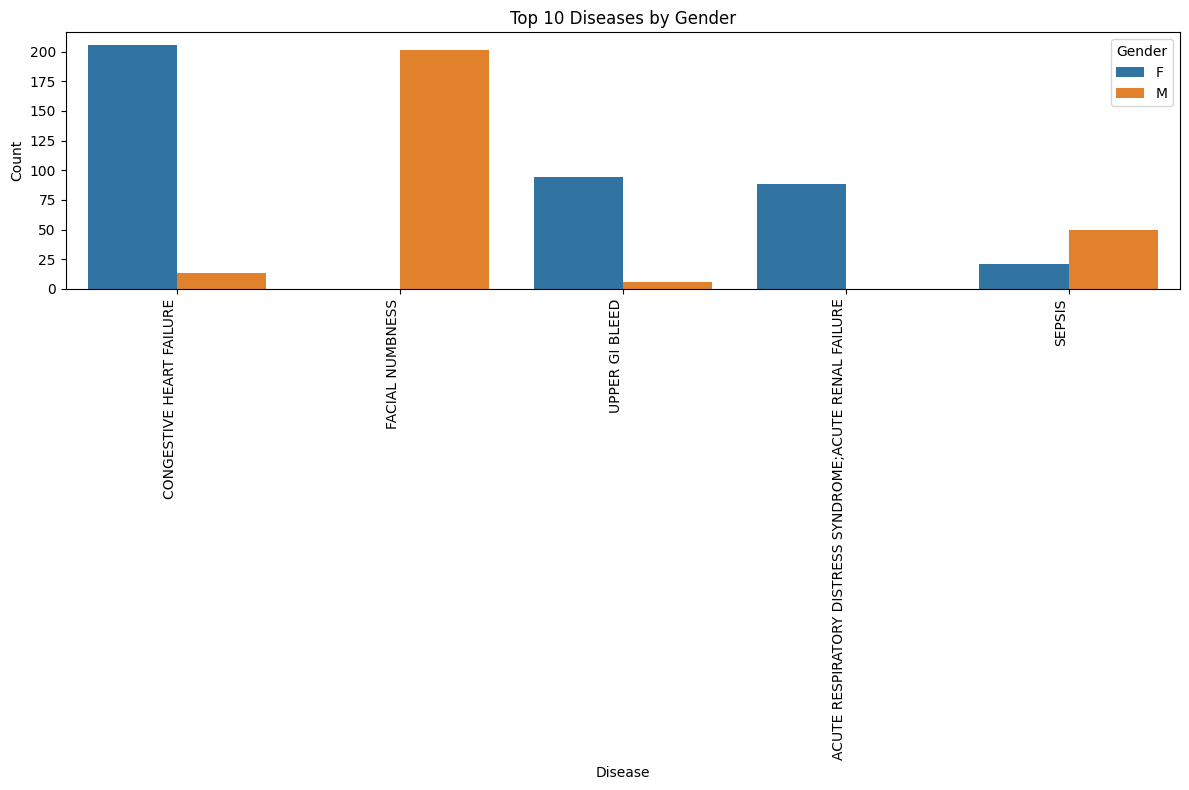

In [ ]:
# Identify the top 10 diseases
top_5_diseases = df['diagnosis'].value_counts().nlargest(5).index

# Filter the DataFrame to include only the top 10 diseases
top_5_df = df[df['diagnosis'].isin(top_5_diseases)]

# Create a count plot for the top 10 diseases by gender
plt.figure(figsize=(12, 8))
sns.countplot(data=top_5_df, x='diagnosis', hue='gender', order=top_5_diseases)
plt.xticks(rotation=90, ha='right')
plt.title('Top 10 Diseases by Gender')
plt.xlabel('Disease')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

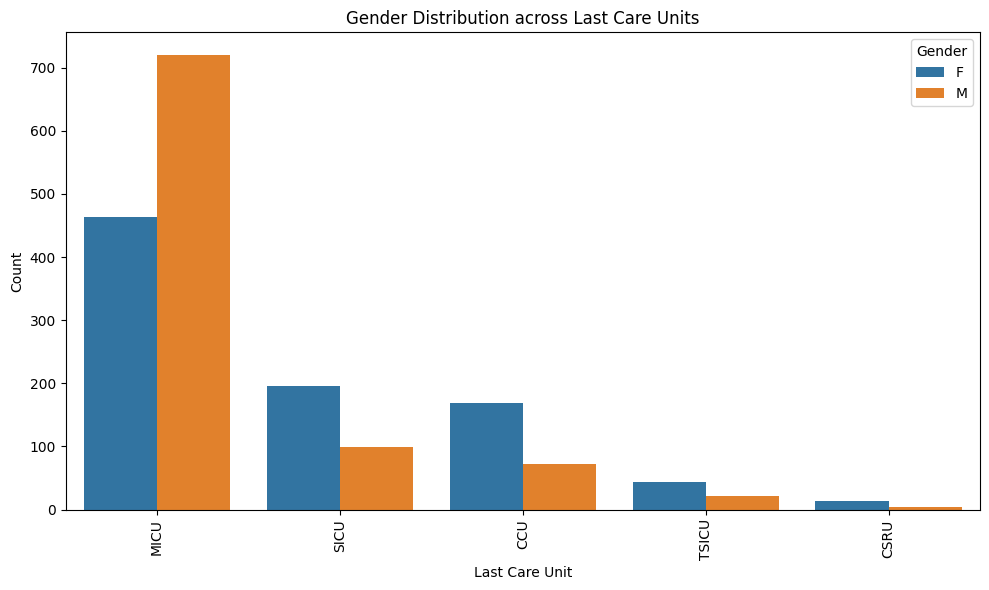

In [ ]:
# Create a count plot for gender vs last care unit
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='last_careunit', hue='gender', order=df['last_careunit'].value_counts().index)
plt.xticks(rotation=90)
plt.title('Gender Distribution across Last Care Units')
plt.xlabel('Last Care Unit')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.tight_layout()
plt.show()


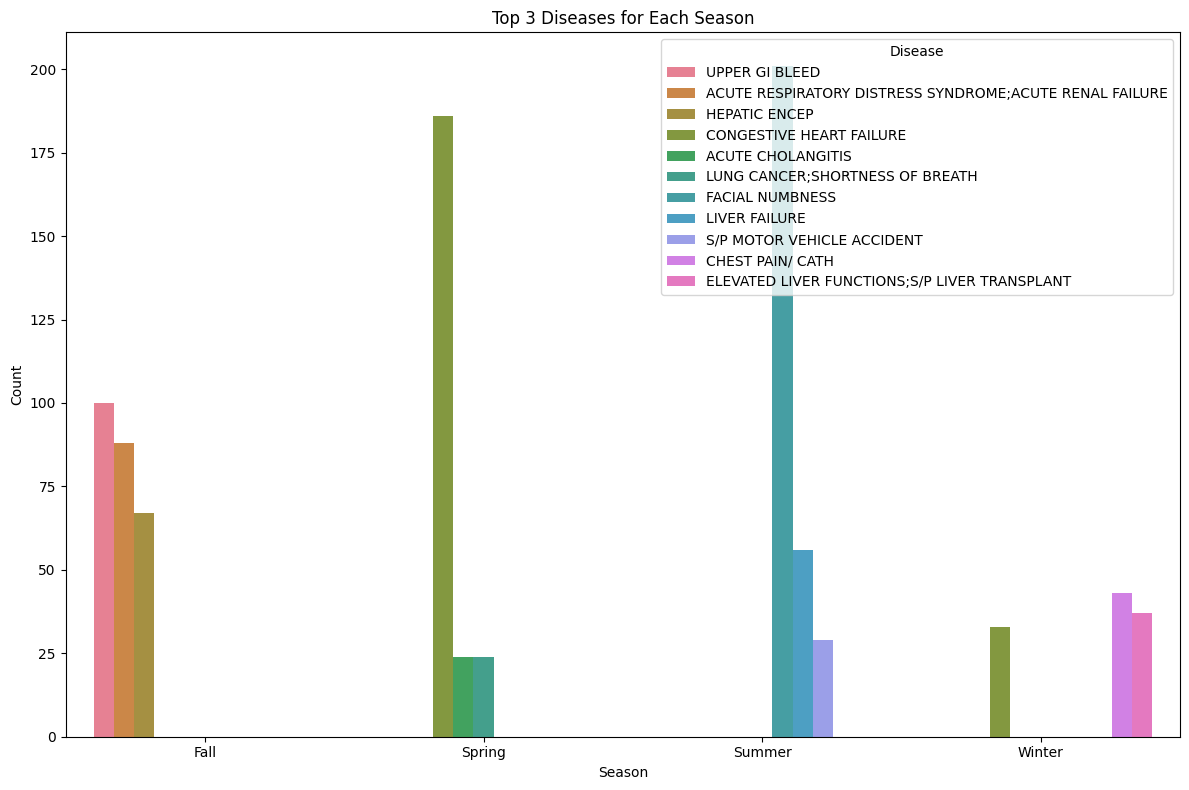

In [ ]:
# Extract month from admittime and create a new column for season
df['admittime'] = pd.to_datetime(df['admittime'])
df['month'] = df['admittime'].dt.month

# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

# Find top 3 diseases for each season
top_diseases = df.groupby(['season', 'diagnosis']).size().reset_index(name='count')
top_diseases = top_diseases.groupby('season').apply(lambda x: x.nlargest(3, 'count')).reset_index(drop=True)

# Plot top 3 diseases for each season
plt.figure(figsize=(12, 8))
sns.barplot(data=top_diseases, x='season', y='count', hue='diagnosis')
plt.title('Top 3 Diseases for Each Season')
plt.xlabel('Season')
plt.ylabel('Count')
plt.legend(title='Disease')
plt.tight_layout()
plt.show()


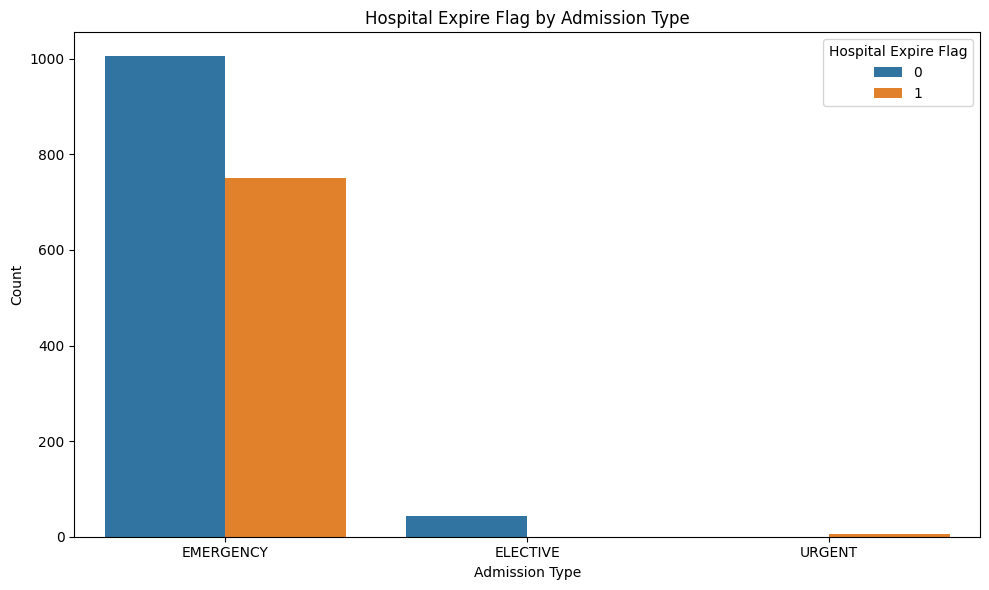

In [ ]:
# Plot hospital expire flag with admission type
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='admission_type', hue='hospital_expire_flag')
plt.title('Hospital Expire Flag by Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Count')
plt.legend(title='Hospital Expire Flag')
plt.tight_layout()
plt.show()


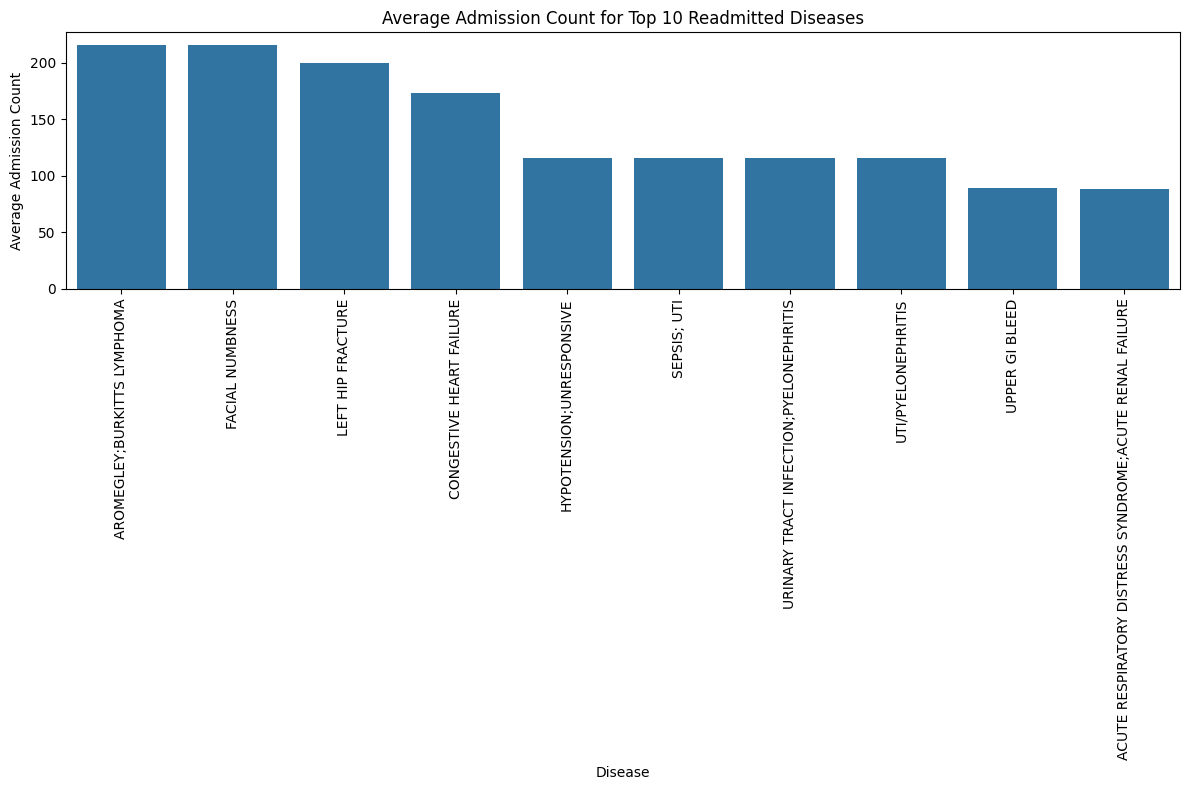

In [ ]:
# Find relationship between readmission and disease
readmission_disease = df.groupby('diagnosis')['admission_count'].mean().reset_index()
top_10_readmitted = readmission_disease.nlargest(10, 'admission_count')

# Plot relationship between readmission and disease for top 10 readmitted diseases
plt.figure(figsize=(12, 8))
sns.barplot(data=top_10_readmitted, x='diagnosis', y='admission_count', order=top_10_readmitted['diagnosis'])
plt.xticks(rotation=90)
plt.title('Average Admission Count for Top 10 Readmitted Diseases')
plt.xlabel('Disease')
plt.ylabel('Average Admission Count')
plt.tight_layout()
plt.show()


# INSIGHTS


**Frequent Readmissions:** A significant number of patients, specifically those with 3 or more admissions, are predominantly from a few subject IDs. This indicates potential chronic conditions or complications leading to repeated hospital visits.

**Gender Distribution:** A balance in gender distribution suggests a need to investigate if there are gender-specific trends or disparities in diagnoses, treatments, or outcomes.

**Ethnicity and Diagnoses:** Certain diagnoses are more prevalent in specific ethnic groups. For example, "HEPATIC ENCEP" is most common among "AMERICAN INDIAN/ALASKA NATIVE" and "LUNG CANCER; SHORTNESS OF BREATH" among "ASIAN". This indicates potential areas for targeted public health interventions or further research into genetic or environmental factors.

**High Mortality Diagnoses:** Diagnoses like "ABDOMINAL PAIN" and "CHRONIC MYELOGENOUS LEUKEMIA; TRANSFUSION REACTION" have a 100% mortality rate in the dataset. It suggests these cases might be severe or complications could be leading to high mortality rates.

**Utilization of ICU:** A significant proportion of procedures are performed in the ICU compared to other cost centers, highlighting the critical nature of care in these units.